<div align="center" dir="rtl" style="direction:rtl;text-align:center;">

<p><img src="../src/logo.png" alt="لوگوی مجموعهٔ آزمون‌های آزمایشی هوش مصنوعی" width="400"></p>
<p><strong>مجموعهٔ آزمون‌های آزمایشی هوش مصنوعی</strong></p>
<p>طراح: nevertheless</p>
<h1>مهرهای فراموش‌شدهٔ سلطنتی</h1>
<p>سطح ۲ · طبقه‌بندی خطی و مهندسی ویژگی دوبعدی</p>
<p><strong>هشت‌پا سه قلب دارد؛ دو قلب خون را به آبشش‌ها می‌فرستند و یکی به بدن.</strong></p>

</div>

<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## مأموریت شما

در زیرزمین کتابخانهٔ سلطنتی، نقشه‌ای از ۲۰۰۰ مهر باستانی پیدا شده است. هر مهر روی یک خانه از صفحه‌ای مختصات‌دار قرار دارد و برچسب آن `0` یا `1` است. قانون رنگ‌آمیزی از یاد رفته؛ شما باید از روی مختصات `(x, y)`، برچسب مهرهای تازه را پیش‌بینی کنید.

نقشه فقط مختصات را نشان می‌دهد. مدل نهایی باید **کاملاً خطی** باشد، اما می‌توانید مختصات را با تبدیل‌های ریاضیِ صریح به ویژگی‌های تازه تبدیل کنید.

### داده‌ها

| فایل | ستون‌ها | کاربرد |
|---|---|---|
| `data/train/train.csv` | `id`, `x`, `y`, `label` | آموزش |
| `data/validation/validation.csv` | `id`, `x`, `y`, `label` | ارزیابی محلی |
| `data/test/test.csv` | `id`, `x`, `y` | پیش‌بینی نهایی |

مختصات در بازه‌ای تقریباً از `-6` تا `+6` قرار دارند. شناسه فقط برای اتصال پیش‌بینی به ردیف درست است؛ آن را به‌عنوان ویژگی استفاده نکنید. برچسب `0` یا `1` است.

### محدودیت‌ها و معیار

کتابخانه‌های مجاز: Python استاندارد، `numpy`, `pandas`, `matplotlib`, `scikit-learn`. مدل نهایی باید یک طبقه‌بند خطی مثل `LogisticRegression` یا `LinearSVC` باشد. درخت، شبکهٔ عصبی، مدل kernel و ابزار خودکار تولید ویژگی چندجمله‌ای مجاز نیستند؛ مهندسی ویژگی باید آشکار و دستی باشد. مقیاس‌بندی ویژگی‌ها مجاز است.

معیار **Accuracy** است. baseline برابر دقت پیش‌بینی کلاس پرتکرار (حدود ۰٫۵) و هدف عملکرد نزدیک به کامل حداقل `0.95` است. نمره: کمتر از baseline صفر، در baseline پنج، از baseline تا هدف خطی تا ۱۹، و Accuracy حداقل ۰٫۹۵ نمرهٔ ۲۰ می‌گیرد.

### تصویرسازی سه‌بعدی ویژگی

تابع `plot_3d_feature_space` مختصات را روی محورهای `x` و `y` می‌گذارد و مقدار یک ویژگی ساخته‌شده را روی محور `z` رسم می‌کند. رنگ هر نقطه کلاس واقعی را نشان می‌دهد و صفحهٔ افقی، آستانهٔ تصمیم را مشخص می‌کند. تابع را با ویژگی خودتان صدا بزنید تا ببینید آیا دو کلاس در فضای ویژگی بهتر از صفحهٔ دوبعدی اولیه جدا می‌شوند.

### فایل ارسال

فایل `submission.csv` باید دقیقاً ستون‌های `id,prediction` را داشته باشد؛ برای هر ردیف test یک پیش‌بینی دودویی بنویسید. متغیر نهایی پیش‌بینی باید `predictions` باشد.

</div>

<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۱. بارگذاری و مشاهدهٔ داده‌ها

داده‌ها را بخوانید، نسبت دو کلاس را بررسی و نقاط را در صفحهٔ `(x,y)` رسم کنید. آیا یک مرز مستقیم می‌تواند این الگو را جدا کند؟

</div>

sizes: 1400 300 300
train class counts:
 label
0    687
1    713
Name: count, dtype: int64


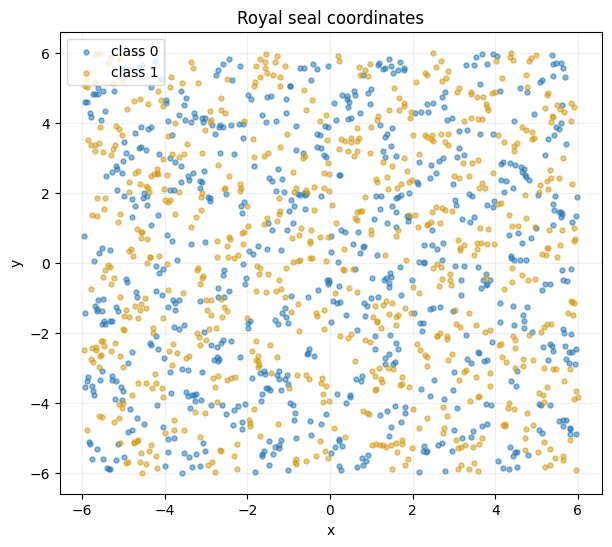

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
DATA=Path("data")
train_df=pd.read_csv(DATA/"train"/"train.csv")
validation_df=pd.read_csv(DATA/"validation"/"validation.csv")
test_df=pd.read_csv(DATA/"test"/"test.csv")
print("sizes:",len(train_df),len(validation_df),len(test_df))
print("train class counts:\n",train_df.label.value_counts().sort_index())
fig,ax=plt.subplots(figsize=(7,6))
for cls,color,name in [(0,"#2878b5","class 0"),(1,"#d49b18","class 1")]:
 d=train_df[train_df.label==cls];ax.scatter(d.x,d.y,s=13,alpha=.55,color=color,label=name)
ax.set(xlabel="x",ylabel="y",title="Royal seal coordinates");ax.legend();ax.grid(alpha=.2);plt.show()


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۲. baseline خطی روی مختصات خام

یک `LogisticRegression` را فقط روی `x` و `y` آموزش دهید و Accuracy آن را روی validation گزارش کنید.

</div>

In [2]:
raw_model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000))
raw_model.fit(train_df[["x","y"]],train_df.label)
raw_pred=raw_model.predict(validation_df[["x","y"]])
print("Raw-coordinate validation accuracy:",accuracy_score(validation_df.label,raw_pred))


Raw-coordinate validation accuracy: 0.48333333333333334


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۳. ابزار مشاهدهٔ فضای ویژگی سه‌بعدی

تابع زیر آماده است. `feature_fn` باید برای آرایه‌های مختصات، یک مقدار ویژگی هم‌اندازه برگرداند. نقاط با برچسب واقعی رنگ می‌شوند و صفحهٔ افقی آستانه را نشان می‌دهد.

</div>

In [3]:
def plot_3d_feature_space(frame, feature_fn, feature_name="engineered feature", threshold=0.0, grid_size=50):
    """Plot (x, y, feature_fn(x,y)) and a horizontal threshold plane."""
    from matplotlib.lines import Line2D
    x=frame["x"].to_numpy(float);y=frame["y"].to_numpy(float);labels=frame["label"].to_numpy(int)
    pad=0.15;xs=np.linspace(x.min()-pad,x.max()+pad,grid_size);ys=np.linspace(y.min()-pad,y.max()+pad,grid_size);X,Y=np.meshgrid(xs,ys)
    Z=np.asarray(feature_fn(X,Y),dtype=float)
    if Z.shape==():Z=np.full_like(X,float(Z))
    if Z.shape!=X.shape:Z=np.broadcast_to(Z,X.shape)
    fig=plt.figure(figsize=(9,7));ax=fig.add_subplot(111,projection="3d")
    ax.plot_surface(X,Y,Z,cmap="coolwarm",alpha=.18,linewidth=0,antialiased=True)
    low=min(float(np.nanmin(Z)),float(threshold));high=max(float(np.nanmax(Z)),float(threshold));span=max(high-low,1e-3)
    ax.plot_surface(X,Y,np.full_like(X,threshold),color="gray",alpha=.18,shade=False)
    colors={0:"#2878b5",1:"#d49b18"}
    for cls in (0,1):
        mask=labels==cls;z=np.asarray(feature_fn(x[mask],y[mask]),dtype=float)
        ax.scatter(x[mask],y[mask],z,s=18,alpha=.8,color=colors[cls],edgecolors="none")
    handles=[Line2D([0],[0],marker="o",color="w",markerfacecolor=colors[c],label=f"class {c}",markersize=8) for c in (0,1)]
    handles.append(Line2D([0],[0],color="gray",alpha=.6,label=f"decision level = {threshold:g}"))
    ax.set(xlabel="x",ylabel="y",zlabel=feature_name,title=f"3D feature view: {feature_name}")
    ax.legend(handles=handles);ax.view_init(elev=28,azim=-55);fig.tight_layout();plt.show()
    return fig,ax


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۴. مهندسی ویژگی

قانون پنهان به زوج‌وفرد بودن خانه‌های شبکه مربوط است. یک تبدیل ریاضی صریح از مختصات بسازید. سپس همان ویژگی را با تابع سه‌بعدی بالا بررسی کنید.

</div>

In [4]:
def make_parity_feature(x,y):
    """Return a one-dimensional feature built explicitly from x and y."""
    # TODO: Create a feature that reveals the hidden alternating lattice pattern.
    raise NotImplementedError

# After implementing the feature, inspect its 3D map:
# plot_3d_feature_space(train_df, make_parity_feature, "your feature", threshold=0.0)


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۵. مدل خطی روی ویژگی ساخته‌شده

مدل را با ویژگی(های) مهندسی‌شده آموزش دهید. پیش‌پردازش و مدل فقط باید از train یاد بگیرند؛ نتیجه را با baseline روی validation مقایسه کنید.

</div>

In [ ]:
def build_feature_matrix(frame):
    z=make_parity_feature(frame["x"].to_numpy(float),frame["y"].to_numpy(float))
    return np.asarray(z,dtype=float).reshape(-1,1)

def fit_linear_model(frame):
    X=build_feature_matrix(frame);y=frame["label"].to_numpy(int)
    model=make_pipeline(StandardScaler(),LogisticRegression(C=10.0,max_iter=2000))
    return model.fit(X,y)

engineered_model=fit_linear_model(train_df)
val_pred=engineered_model.predict(build_feature_matrix(validation_df))
print("Validation accuracy:",accuracy_score(validation_df.label,val_pred))


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۶. ارزیابی و نمرهٔ تخمینی

Accuracy و نمرهٔ تخمینی را روی validation گزارش کنید. validation برای انتخاب ایده است و نباید وارد برازش نهایی شود.

</div>

In [ ]:
def score_from_accuracy(acc,baseline=0.50,target=0.95):
    if acc<baseline:return 0
    if acc>=target:return 20
    return min(19,round(5+15*(acc-baseline)/(target-baseline)))

val_accuracy=accuracy_score(validation_df.label,val_pred)
print(f"Validation Accuracy={val_accuracy:.4f}; estimated score={score_from_accuracy(val_accuracy)}/20")


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۷. پیش‌بینی تست و ساخت فایل ارسال

پس از انتخاب ویژگی، مدل را روی train و validation با هم بازآموزی کنید. پیش‌بینی‌های test را در `predictions` بگذارید و فایل ارسال را بسازید.

</div>

In [ ]:
# Refit using both labeled splits, then create the fixed submission format.
full_train=pd.concat([train_df,validation_df],ignore_index=True)
final_model=fit_linear_model(full_train)
predictions=np.asarray(final_model.predict(build_feature_matrix(test_df)),dtype=int)
assert len(predictions)==len(test_df) and set(np.unique(predictions)).issubset({0,1})
submission=pd.DataFrame({"id":test_df.id,"prediction":predictions})
assert submission.id.is_unique and submission.columns.tolist()==["id","prediction"]
submission.to_csv("submission.csv",index=False)
print(f"Created submission.csv with {len(submission)} rows.")
